# Experiment 7 :: Sentiment Analysis on IMDB Movie Reviews

- 7.1 Logistic Regression (TF-IDF features)
- 7.2 LSTM
- 7.3 Vanilla Transformer (encoder only)
- 7.4 BERT pretrained model (fine-tuned)
- 7.5 Comparative analysis using Precision, Recall, F1 and Confusion Matrix

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib seaborn torch transformers

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import re
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, classification_report

torch.manual_seed(42)
np.random.seed(42)

device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


## Dataset

In [2]:
dataset_url = 'https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv'
if not os.path.exists('IMDB-Dataset.csv'):
    urllib.request.urlretrieve(dataset_url, 'IMDB-Dataset.csv')

full_df = pd.read_csv('IMDB-Dataset.csv')
print('Full dataset:', full_df.shape)

df = full_df.groupby('sentiment', group_keys=False).sample(5000, random_state=42).reset_index(drop=True)
print('Using a smaller chunk:', df.shape)
print(df['sentiment'].value_counts())
df.head()

Full dataset: (50000, 2)
Using a smaller chunk: (10000, 2)
sentiment
negative    5000
positive    5000
Name: count, dtype: int64


,review,sentiment
0,I was looking forward to seeing Bruce Willis i...,negative
1,Bugs Bunny accidentally ends up at the South P...,negative
2,I find it difficult to comprehend what makes v...,negative
3,It's been said several times - not least by me...,negative
4,New rule. Nobody is allowed to make any more Z...,negative


In [3]:
def clean_text(text):
    text = text.replace('<br />', ' ')
    text = re.sub(r'[^a-zA-Z\']', ' ', text)
    return ' '.join(text.lower().split())

df['clean_review'] = df['review'].apply(clean_text)
df['label'] = (df['sentiment'] == 'positive').astype(int)

train_df, test_df = train_test_split(df, test_size=2000, stratify=df['label'], random_state=42)
y_train = train_df['label'].values
y_test = test_df['label'].values

print('Train:', len(train_df), ' Test:', len(test_df))
print('Average review length (words):', int(df['clean_review'].str.split().str.len().mean()))

Train: 8000  Test: 2000
Average review length (words): 229


In [4]:
results = {}

def evaluate(model_name, y_true, y_pred):
    results[model_name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
    }
    print(model_name)
    print(classification_report(y_true, y_pred, target_names=['negative', 'positive'], digits=4))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'positive'], yticklabels=['negative', 'positive'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(model_name)
    plt.show()

## 7.1 Logistic Regression

Training time: 0.1s
Logistic Regression
              precision    recall  f1-score   support

    negative     0.8969    0.8700    0.8832      1000
    positive     0.8738    0.9000    0.8867      1000

    accuracy                         0.8850      2000
   macro avg     0.8853    0.8850    0.8850      2000
weighted avg     0.8853    0.8850    0.8850      2000



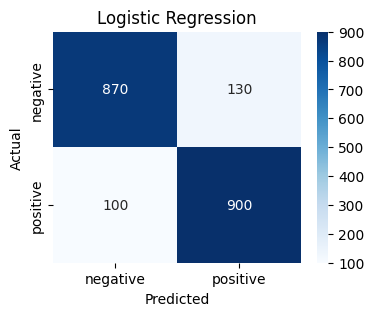

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), stop_words='english')
X_train_tfidf = tfidf.fit_transform(train_df['clean_review'])
X_test_tfidf = tfidf.transform(test_df['clean_review'])

start = time.time()
log_reg = LogisticRegression(max_iter=1000, C=5)
log_reg.fit(X_train_tfidf, y_train)
print(f'Training time: {time.time() - start:.1f}s')

lr_pred = log_reg.predict(X_test_tfidf)
evaluate('Logistic Regression', y_test, lr_pred)

In [6]:
feature_names = np.array(tfidf.get_feature_names_out())
weights = log_reg.coef_[0]
print('Most positive words:', list(feature_names[np.argsort(weights)[-15:]][::-1]))
print('Most negative words:', list(feature_names[np.argsort(weights)[:15]]))

Most positive words: ['great', 'excellent', 'love', 'perfect', 'best', 'wonderful', 'hilarious', 'loved', 'amazing', 'brilliant', 'beautiful', 'fun', 'fantastic', 'favorite', 'series']
Most negative words: ['worst', 'bad', 'awful', 'poor', 'boring', 'waste', 'worse', 'terrible', 'instead', 'stupid', 'dull', 'horrible', 'supposed', 'poorly', 'wasted']


## Preparing sequences for LSTM and Transformer

In [7]:
from collections import Counter

max_words = 20000
max_len = 250

word_counts = Counter(word for review in train_df['clean_review'] for word in review.split())
word_index = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(max_words - 2))}

def to_sequence(review):
    ids = [word_index.get(word, 1) for word in review.split()][:max_len]
    return [0] * (max_len - len(ids)) + ids

X_train_seq = torch.tensor([to_sequence(r) for r in train_df['clean_review']])
X_test_seq = torch.tensor([to_sequence(r) for r in test_df['clean_review']])
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

print('Vocabulary size:', len(word_index) + 2)
print('Sequence shape:', X_train_seq.shape)

Vocabulary size: 20000
Sequence shape: torch.Size([8000, 250])


In [8]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train_seq, y_train_tensor), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_seq), batch_size=256)

def train_model(model, epochs, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss, correct = 0, 0
        start = time.time()
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * len(x_batch)
            correct += ((logits > 0).float() == y_batch).sum().item()

        train_loss = total_loss / len(train_loader.dataset)
        train_acc = correct / len(train_loader.dataset)
        history.append((train_loss, train_acc))
        print(f'Epoch {epoch + 1}/{epochs}  loss {train_loss:.4f}  acc {train_acc:.4f}  ({time.time() - start:.0f}s)')
    return history

def predict(model):
    model.eval()
    predictions = []
    with torch.no_grad():
        for (x_batch,) in test_loader:
            logits = model(x_batch.to(device))
            predictions.extend((logits > 0).int().cpu().tolist())
    return np.array(predictions)

## 7.2 LSTM

In [9]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        return self.fc(self.dropout(hidden[-1])).squeeze(1)

lstm_model = LSTMClassifier(max_words)
print(lstm_model)
print('Parameters:', sum(p.numel() for p in lstm_model.parameters()))

LSTMClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)
Parameters: 2692225


Epoch 1/6  loss 0.6778  acc 0.5590  (2s)
Epoch 2/6  loss 0.5841  acc 0.6934  (1s)
Epoch 3/6  loss 0.4815  acc 0.7741  (1s)
Epoch 4/6  loss 0.3896  acc 0.8320  (1s)
Epoch 5/6  loss 0.3037  acc 0.8738  (1s)
Epoch 6/6  loss 0.2371  acc 0.9124  (1s)
LSTM
              precision    recall  f1-score   support

    negative     0.7876    0.7270    0.7561      1000
    positive     0.7465    0.8040    0.7742      1000

    accuracy                         0.7655      2000
   macro avg     0.7671    0.7655    0.7652      2000
weighted avg     0.7671    0.7655    0.7652      2000



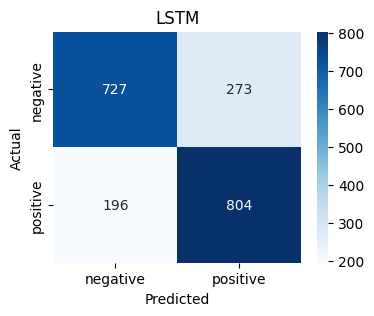

In [11]:
lstm_history = train_model(lstm_model, epochs=6)
lstm_pred = predict(lstm_model)
evaluate('LSTM', y_test, lstm_pred)

## 7.3 Vanilla Transformer

In [12]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, num_heads=4, num_layers=2, ff_dim=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.position_embedding = nn.Embedding(max_len, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model, num_heads, ff_dim, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        padding_mask = x == 0
        out = self.embedding(x) + self.position_embedding(positions)
        out = self.encoder(out, src_key_padding_mask=padding_mask)
        keep = (~padding_mask).unsqueeze(-1).float()
        pooled = (out * keep).sum(1) / keep.sum(1).clamp(min=1)
        return self.fc(self.dropout(pooled)).squeeze(1)

transformer_model = TransformerClassifier(max_words)
print('Parameters:', sum(p.numel() for p in transformer_model.parameters()))

Parameters: 2857089


Epoch 1/6  loss 0.6296  acc 0.6296  (3s)
Epoch 2/6  loss 0.4858  acc 0.7658  (3s)
Epoch 3/6  loss 0.3859  acc 0.8295  (3s)
Epoch 4/6  loss 0.2970  acc 0.8759  (3s)
Epoch 5/6  loss 0.2157  acc 0.9146  (3s)
Epoch 6/6  loss 0.1428  acc 0.9493  (3s)
Vanilla Transformer
              precision    recall  f1-score   support

    negative     0.7667    0.8480    0.8053      1000
    positive     0.8300    0.7420    0.7835      1000

    accuracy                         0.7950      2000
   macro avg     0.7984    0.7950    0.7944      2000
weighted avg     0.7984    0.7950    0.7944      2000



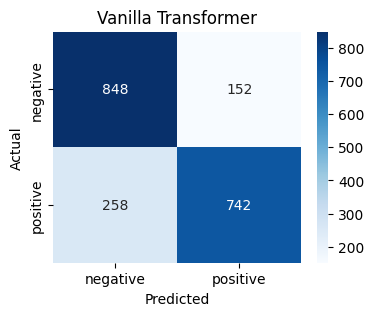

In [13]:
transformer_history = train_model(transformer_model, epochs=6, lr=5e-4)
transformer_pred = predict(transformer_model)
evaluate('Vanilla Transformer', y_test, transformer_pred)

## 7.4 BERT (bert-base-uncased, fine-tuned)

Fine-tuning BERT on all 8000 training reviews takes too long on my laptop, so it is fine-tuned on 2000 of them and tested on the same 2000 test reviews as the other models.

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

lstm_model.cpu()
transformer_model.cpu()
if device == 'mps':
    torch.mps.empty_cache()

bert_name = 'bert-base-uncased'
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModelForSequenceClassification.from_pretrained(bert_name, num_labels=2).to(device)

bert_train_df = train_df.groupby('label', group_keys=False).sample(1000, random_state=42)
bert_max_len = 256

def bert_encode(reviews):
    reviews = [r.replace('<br />', ' ') for r in reviews]
    return bert_tokenizer(reviews, truncation=True, padding='max_length', max_length=bert_max_len, return_tensors='pt')

train_encodings = bert_encode(list(bert_train_df['review']))
test_encodings = bert_encode(list(test_df['review']))

bert_train_loader = DataLoader(
    TensorDataset(train_encodings['input_ids'], train_encodings['attention_mask'], torch.tensor(bert_train_df['label'].values)),
    batch_size=8, shuffle=True)
bert_test_loader = DataLoader(TensorDataset(test_encodings['input_ids'], test_encodings['attention_mask']), batch_size=16)

print('BERT train size:', len(bert_train_df))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT train size: 2000


In [15]:
from transformers import get_linear_schedule_with_warmup

bert_epochs = 3
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=2e-5)
total_steps = len(bert_train_loader) * bert_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

for epoch in range(bert_epochs):
    bert_model.train()
    total_loss, correct = 0, 0
    start = time.time()
    for input_ids, attention_mask, labels in bert_train_loader:
        input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
        optimizer.zero_grad()
        output = bert_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        output.loss.backward()
        nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += output.loss.item() * len(labels)
        correct += (output.logits.argmax(1) == labels).sum().item()
    print(f'Epoch {epoch + 1}/{bert_epochs}  loss {total_loss / len(bert_train_df):.4f}  acc {correct / len(bert_train_df):.4f}  ({time.time() - start:.0f}s)')

Epoch 1/3  loss 0.4812  acc 0.7675  (62s)
Epoch 2/3  loss 0.2509  acc 0.9195  (62s)
Epoch 3/3  loss 0.1225  acc 0.9715  (62s)


BERT
              precision    recall  f1-score   support

    negative     0.9390    0.8770    0.9069      1000
    positive     0.8846    0.9430    0.9129      1000

    accuracy                         0.9100      2000
   macro avg     0.9118    0.9100    0.9099      2000
weighted avg     0.9118    0.9100    0.9099      2000



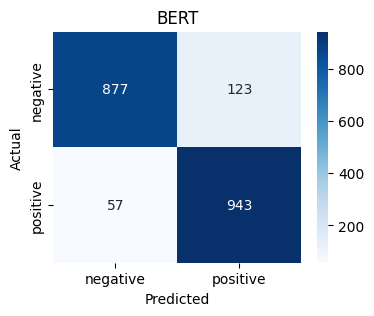

In [16]:
bert_model.eval()
bert_pred = []
with torch.no_grad():
    for input_ids, attention_mask in bert_test_loader:
        logits = bert_model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device)).logits
        bert_pred.extend(logits.argmax(1).cpu().tolist())
bert_pred = np.array(bert_pred)

evaluate('BERT', y_test, bert_pred)

## 7.5 Comparative analysis

In [17]:
comparison = pd.DataFrame(results).T.round(4)
comparison

,Accuracy,Precision,Recall,F1
Logistic Regression,0.8850,0.8738,0.900,0.8867
LSTM,0.7655,0.7465,0.804,0.7742
Vanilla Transformer,0.7950,0.8300,0.742,0.7835
BERT,0.9100,0.8846,0.943,0.9129


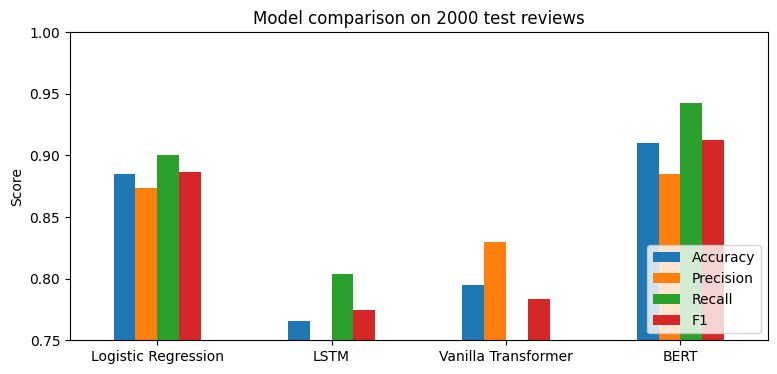

In [18]:
comparison.plot(kind='bar', figsize=(9, 4), ylim=(0.75, 1.0), rot=0)
plt.title('Model comparison on 2000 test reviews')
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.show()

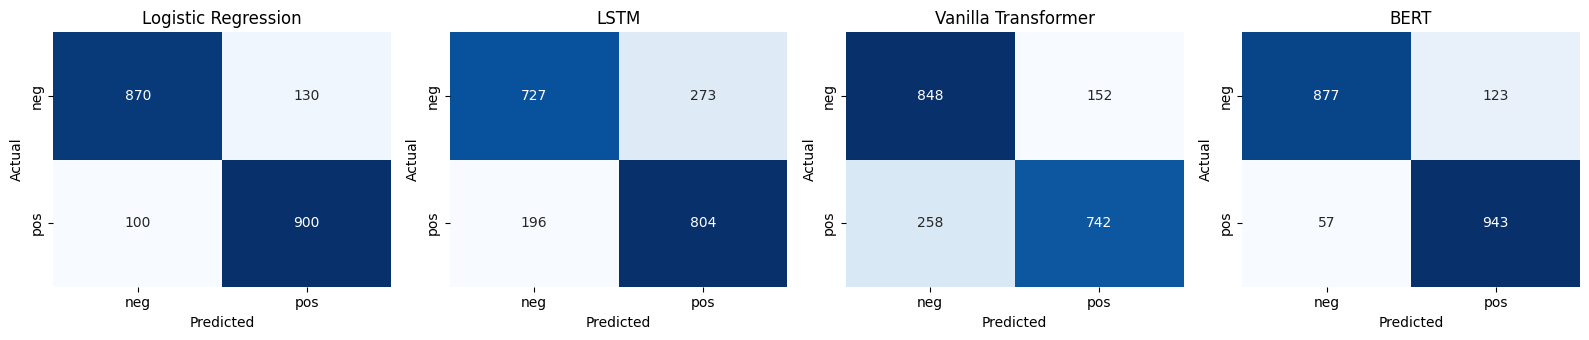

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
all_predictions = {'Logistic Regression': lr_pred, 'LSTM': lstm_pred, 'Vanilla Transformer': transformer_pred, 'BERT': bert_pred}
for ax, (name, pred) in zip(axes, all_predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['neg', 'pos'], yticklabels=['neg', 'pos'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [20]:
best_model = comparison['F1'].idxmax()
print('Best model by F1:', best_model, comparison.loc[best_model, 'F1'])

for name, pred in all_predictions.items():
    cm = confusion_matrix(y_test, pred)
    print(f'{name:<22} false positives: {cm[0, 1]:<5} false negatives: {cm[1, 0]}')

Best model by F1: BERT 0.9129
Logistic Regression    false positives: 130   false negatives: 100
LSTM                   false positives: 273   false negatives: 196
Vanilla Transformer    false positives: 152   false negatives: 258
BERT                   false positives: 123   false negatives: 57


## Micro vs Macro F1

- Macro F1: F1 of each class separately, then the plain average
- Micro F1: TP, FP and FN added over both classes first, then one F1 (same as accuracy for single label classification)
- Weighted F1: per class F1 averaged by class support

In [21]:
from sklearn.metrics import f1_score

f1_rows = {}
for name, pred in all_predictions.items():
    f1_rows[name] = {
        'F1 negative': f1_score(y_test, pred, pos_label=0),
        'F1 positive': f1_score(y_test, pred, pos_label=1),
        'Macro F1': f1_score(y_test, pred, average='macro'),
        'Micro F1': f1_score(y_test, pred, average='micro'),
        'Weighted F1': f1_score(y_test, pred, average='weighted'),
        'Accuracy': accuracy_score(y_test, pred),
    }

f1_comparison = pd.DataFrame(f1_rows).T.round(4)
f1_comparison

,F1 negative,F1 positive,Macro F1,Micro F1,Weighted F1,Accuracy
Logistic Regression,0.8832,0.8867,0.8850,0.8850,0.8850,0.8850
LSTM,0.7561,0.7742,0.7652,0.7655,0.7652,0.7655
Vanilla Transformer,0.8053,0.7835,0.7944,0.7950,0.7944,0.7950
BERT,0.9069,0.9129,0.9099,0.9100,0.9099,0.9100


### Observations

- BERT is the best model with F1 0.913 and accuracy 0.910, even though it was fine-tuned on only 2000 reviews, because it already knows English from pretraining. It also has the fewest false negatives (57).
- Logistic Regression on TF-IDF with bigrams comes second (F1 0.887) and trains in under a second, so it is a very strong baseline for this dataset.
- The LSTM (F1 0.774) and the vanilla Transformer (F1 0.784) are trained from scratch on 8000 reviews. Both reach over 90% training accuracy but under 80% on the test set, so they overfit with this little data.
- The Transformer is biased towards predicting negative (recall 0.742 on positive reviews), while the LSTM is biased the other way (273 false positives).
- Macro and micro F1 are almost the same for every model (BERT 0.9099 vs 0.9100) because the test set is balanced, 1000 reviews per class. On imbalanced data macro F1 would be lower, since it gives the small class equal weight.
- Overall: pretrained BERT > TF-IDF + Logistic Regression > Transformer from scratch ≈ LSTM from scratch.